In [12]:
import numpy as np
from hcipy import *
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import sys
import os

sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))

from adcFitter_onsky import AdcFitter

In [13]:
#system params
wavelength = 764E-9
bw = 120E-9
grating_angle = 28
grating_freq = 47

ADC = AdcFitter(wavelength=wavelength,grating_freq=grating_freq,grating_angle=grating_angle)

In [ ]:
#ok so we're going to try and compare the current style of fitting (elliptical gaussian) to the idea of taking many slices of gaussians and then drawing a line to connect their peaks to find the orientation
#first, define a new class for the optimizer

class sliced_gauss:
    def __init__(self,wavelength=656E-9,bandwidth=100E-9,grating_angle=28,grating_freq=47):
        self.wavelength = wavelength
        self.bandwidth = bandwidth
        self.grating_angle = grating_angle
        self.grating_freq = grating_freq
        self.normalized_wavelength = wavelength / 656E-9 #normalizing the wavelengths to the ha values
        self.normalized_bandwidth = bandwidth / 656E-9 
        self.maxiter = 5
        self.control_mtx = np.matrix([[0,0],])
        self.current_speckle = None
        self.centers = []
    
    def make_gaussian(self, mu_x, sigma_x):
        def func(grid):
            new_grid = grid.shifted([-mu_x, 0])
            x = new_grid.x / sigma_x
            r2 = x**2 
            return Field(np.exp(-0.5 * r2), grid)
        return func


160000
(160000,)
[-24.4848223  -45.85171455]
1600


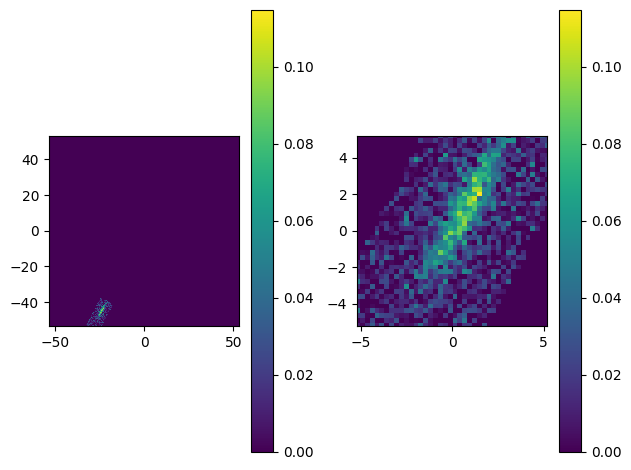

In [45]:
img = read_field('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/fields/sats/7725_0offset.fits')[0]

img = ADC.crop_image(img)

img = ADC.find_speckle(img,2) # you don't need to do this because the cropped frame will exclude the rest of the image
#but for now we keep it because it allows us to isolate each speckle

plt.subplot(1,2,1)
imshow_field(img)
plt.colorbar()

ADC.set_measurement(img)
print(img.size)

extent=40
center_of_intensity = np.array([sum(img*img.grid.x)/sum(img),sum(img*img.grid.y)/sum(img)])
print(img.shape)
print(center_of_intensity)
img = ADC.window_field(img,[center_of_intensity[0],center_of_intensity[1]],extent,extent)
print(img.size)

plt.subplot(1,2,2)
imshow_field(img)
plt.colorbar()
plt.tight_layout()
plt.show()


(40, 40)


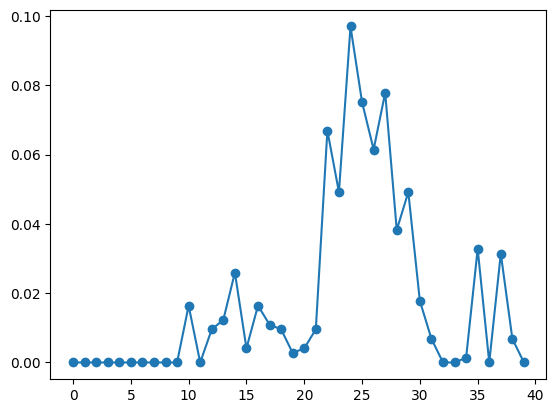

In [ ]:
print(img.shaped.shape)

shaped = img.shaped

plt.plot((shaped[-10,:]),'o-')
#might be a good idea here to start from the middle and truncate it the same way youve been doing for the FWHM measurements